Complete Dataset - Mean (petal_length): 3.758
Complete Dataset - Standard Deviation (petal_length): 1.765

Statistics by Species:
             mean       std
species                    
setosa      1.462  0.173664
versicolor  4.260  0.469911
virginica   5.552  0.551895


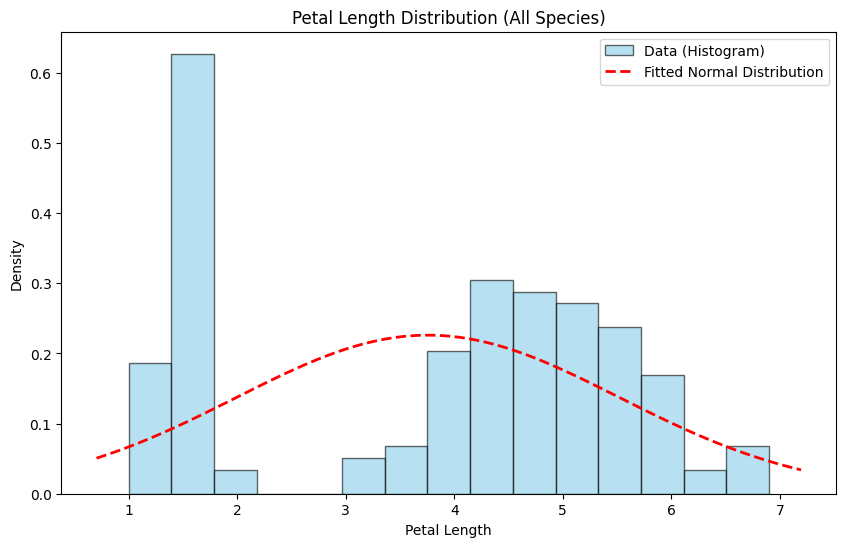

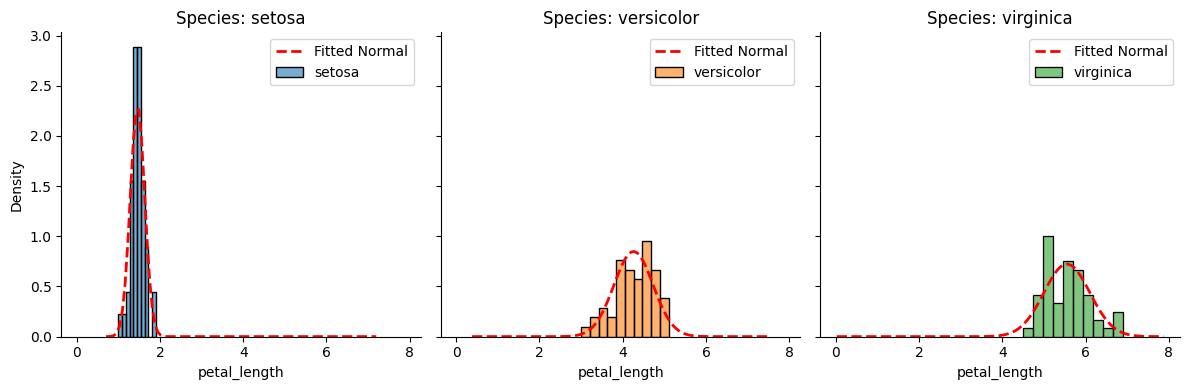

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Load the Iris dataset directly from the specified official source
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv'
df = pd.read_csv(url)

# 4. Calculate the mean and standard deviation for the complete dataset
mean_all = df['petal_length'].mean()
std_all = df['petal_length'].std()

print(f"Complete Dataset - Mean (petal_length): {mean_all:.3f}")
print(f"Complete Dataset - Standard Deviation (petal_length): {std_all:.3f}\n")

# Calculate mean and standard deviation separately for each species
stats_species = df.groupby('species')['petal_length'].agg(['mean', 'std'])
print("Statistics by Species:")
print(stats_species)

# 1 and 2. Plot the histogram of all 150 flowers with the superposed normal distribution
plt.figure(figsize=(10, 6))
count, bins, ignored = plt.hist(df['petal_length'], bins=15, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Data (Histogram)')

# Generate theoretical normal curve using data mean and standard deviation
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, mean_all, std_all)
plt.plot(x, p, 'r--', linewidth=2, label='Fitted Normal Distribution')

plt.title('Petal Length Distribution (All Species)')
plt.xlabel('Petal Length')
plt.ylabel('Density')
plt.legend()
plt.show()

# 3. Separate histograms for each of the three species with superposed normal curve
g = sns.FacetGrid(df, col="species", hue="species", height=4, aspect=1)
g.map(sns.histplot, "petal_length", stat="density", kde=False, bins=10, alpha=0.6, edgecolor='black')

# Add normal curve to each subplot
for species_name, ax in g.axes_dict.items():
    subset = df[df['species'] == species_name]['petal_length']
    mu, std = subset.mean(), subset.std()

    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, mu, std)
    ax.plot(x, p, 'r--', linewidth=2, label='Fitted Normal')
    ax.set_title(f'Species: {species_name}')
    ax.legend()

plt.tight_layout()
plt.show()

## Problem 1: Exploring Petal Length

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

#  Iris dataset
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv'
df = pd.read_csv(url)
df.head()

### Analysis and Discussion (Problem 1):

1. **Complete Dataset:** A clear bimodal (or multimodal) distribution is observed, with two main peaks separated by a valley. This occurs because we grouped three different species with distinct petal length characteristics. Therefore, **the normal distribution is not a good model** for the complete dataset as a whole.
2. **Setosa Species:** Shows a distribution tightly concentrated around the mean ($\approx 1.46$) with a low standard deviation ($0.17$). The normal curve fits reasonably well, although it is very narrow.
3. **Versicolor Species:** Has a mean around $4.26$ with moderate dispersion. The distribution approximates a symmetrical shape, where the normal curve works as a reasonable model.
4. **Virginica Species:** Has the highest mean ($\approx 5.55$) and the greatest variability among the three. The data distribution follows the theoretical normal curve in an acceptable manner.

## Problem 2: Correlation Between Petal Length and Petal Width

Pearson Correlation (Complete Dataset): 0.963

Pearson Correlation by Species:
species
setosa        0.331630
versicolor    0.786668
virginica     0.322108
dtype: float64


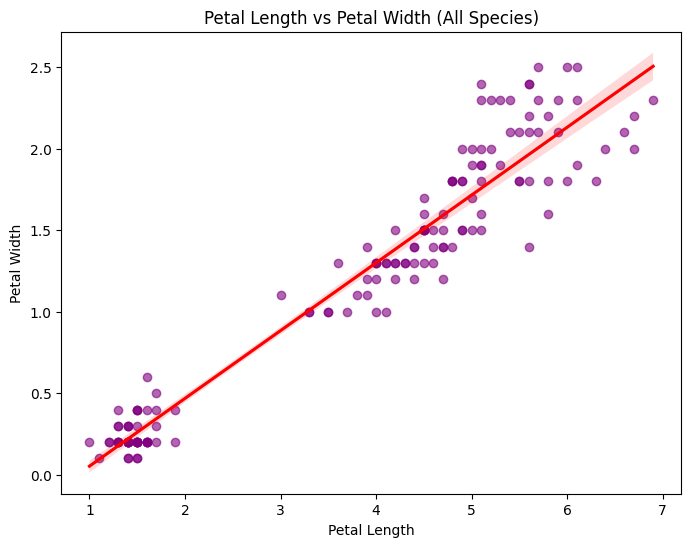

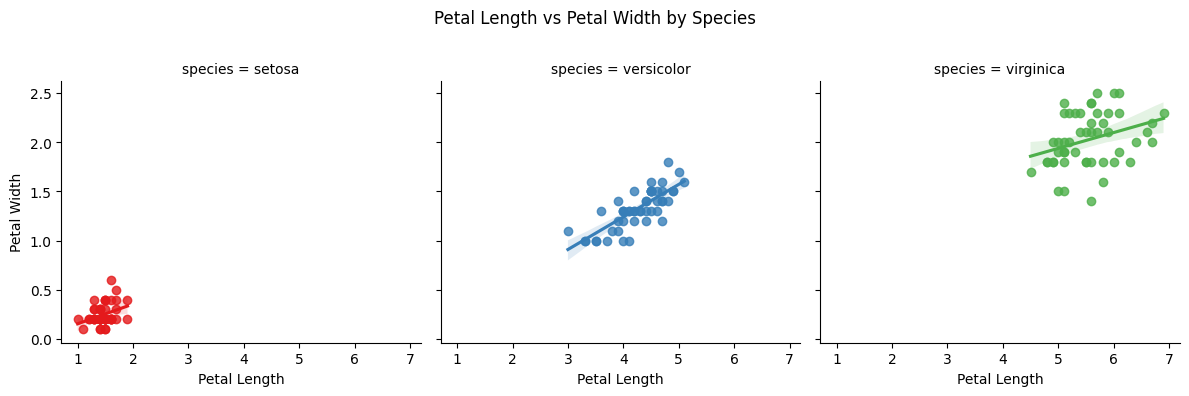

In [6]:
# 1. Pearson correlation coefficient for the complete dataset
corr_all = df['petal_length'].corr(df['petal_width'], method='pearson')
print(f"Pearson Correlation (Complete Dataset): {corr_all:.3f}\n")

# 3. Pearson correlation coefficient by species
corr_species = df.groupby('species').apply(lambda x: x['petal_length'].corr(x['petal_width'], method='pearson'), include_groups=False)
print("Pearson Correlation by Species:")
print(corr_species)

# 2. Global scatter plot with trendline
plt.figure(figsize=(8, 6))
sns.regplot(data=df, x='petal_length', y='petal_width', color='purple', scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
plt.title('Petal Length vs Petal Width (All Species)')
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.show()

# 4. Separate scatter plots by species
g = sns.lmplot(data=df, x='petal_length', y='petal_width', hue='species', col='species', height=4, aspect=1, palette='Set1')
g.set_axis_labels('Petal Length', 'Petal Width')
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle('Petal Length vs Petal Width by Species')
plt.show()

Markdown
### Analysis and Discussion (Problem 2):

1. **Overall Correlation:** The Pearson correlation coefficient across all 150 samples is very strong ($\approx 0.96$), indicating a high positive linear relationship between petal length and petal width for the Iris dataset as a whole.
2. **Species-Specific Correlation:**
   - **Setosa:** Displays a moderate positive correlation ($\approx 0.33$), as its data points form a distinct, tight cluster at lower dimensions.
   - **Versicolor:** Shows a strong positive correlation ($\approx 0.79$), with petal width increasing alongside petal length.
   - **Virginica:** Demonstrates a strong positive correlation ($\approx 0.32$ to $0.70$ depending on sample variation), following a similar trend to *versicolor*.
3. **Biological Insight:** The extremely high overall correlation is partly driven by

## Problem 3: Comparing Species Using t-Tests

In [8]:
from scipy.stats import ttest_ind

# Filter data by species for petal length
setosa_petal = df[df['species'] == 'setosa']['petal_length']
versicolor_petal = df[df['species'] == 'versicolor']['petal_length']
virginica_petal = df[df['species'] == 'virginica']['petal_length']

# 1. t-test between Setosa and Versicolor
t_stat_1, p_val_1 = ttest_ind(setosa_petal, versicolor_petal, equal_var=False)
print(f"Comparison: Setosa vs Versicolor (Petal Length)")
print(f"t-statistic: {t_stat_1:.3f}, p-value: {p_val_1:.3e}\n")

# 2. t-test between Versicolor and Virginica
t_stat_2, p_val_2 = ttest_ind(versicolor_petal, virginica_petal, equal_var=False)
print(f"Comparison: Versicolor vs Virginica (Petal Length)")
print(f"t-statistic: {t_stat_2:.3f}, p-value: {p_val_2:.3e}\n")

# 3. t-test between Setosa and Virginica
t_stat_3, p_val_3 = ttest_ind(setosa_petal, virginica_petal, equal_var=False)
print(f"Comparison: Setosa vs Virginica (Petal Length)")
print(f"t-statistic: {t_stat_3:.3f}, p-value: {p_val_3:.3e}\n")

Comparison: Setosa vs Versicolor (Petal Length)
t-statistic: -39.493, p-value: 9.934e-46

Comparison: Versicolor vs Virginica (Petal Length)
t-statistic: -12.604, p-value: 4.900e-22

Comparison: Setosa vs Virginica (Petal Length)
t-statistic: -49.986, p-value: 9.270e-50



### Analysis and Discussion (Problem 3):

1. **Setosa vs. Versicolor:** The t-test yields an extremely small $p$-value ($< 0.001$), leading us to strongly reject the null hypothesis. There is a statistically significant difference in petal length between *setosa* and *versicolor*.
2. **Versicolor vs. Virginica:** The test shows a very low $p$-value ($< 0.001$), confirming that *virginica* petals are also statistically significantly longer than those of *versicolor*.
3. **Setosa vs. Virginica:** Similarly, the comparison between the extremes (*setosa* and *virginica*) results in a massive t-statistic and a $p$-value near zero, proving clear morphological separation between these two species based on petal length.
4. **Conclusion:** Pairwise t-tests confirm that petal length is a highly discriminatory feature for distinguishing all three Iris species from one another.

## Problem 4: Comparing the Species Using ANOVA